In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [2]:
uploaded = files.upload()
input_name = next(iter(uploaded))
input_path = '/content/' + input_name

print('Input Image:', input_name)

Saving Adad.jpg to Adad.jpg
Input Image: Adad.jpg


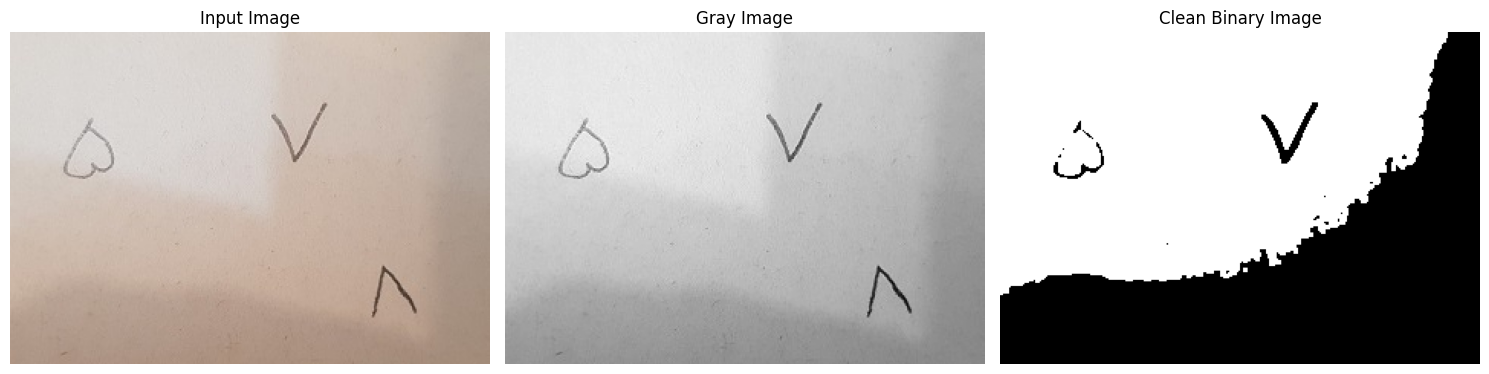

In [3]:
input_image = cv2.imread(input_path)
if input_image is None:
  raise ValueError('Invalid Image Path')

gray_image = cv2.cvtColor(input_image, cv2.COLOR_BGR2GRAY)

blurred_image = cv2.GaussianBlur(gray_image, (5, 5), 0)

_, binary_image = cv2.threshold(blurred_image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

clean_binary = cv2.morphologyEx(binary_image, cv2.MORPH_OPEN, kernel)

contours, hierarchy = cv2.findContours(clean_binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(input_image, cv2.COLOR_BGR2RGB))
plt.title('Input Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gray_image, cmap='gray')
plt.title('Gray Image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(clean_binary, cmap='gray')
plt.title('Clean Binary Image')
plt.axis('off')

plt.tight_layout()
plt.show()

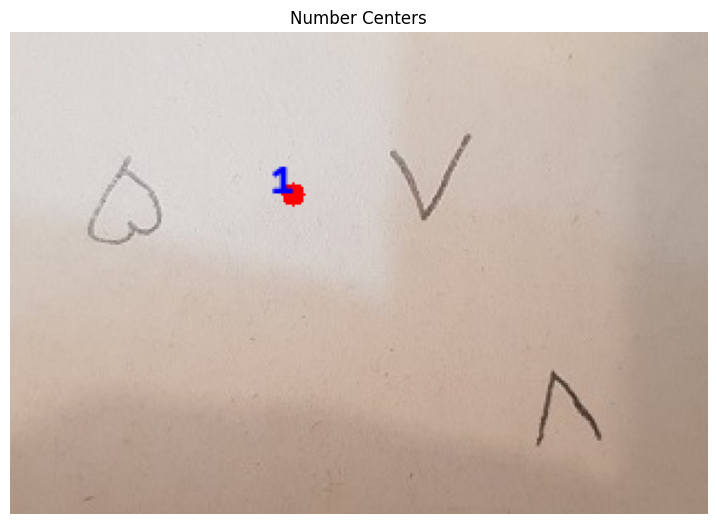

In [4]:
MIN_CONTOUR_AREA = 20

number_contours = []
centers = []

for contour in contours:
  area = cv2.contourArea(contour)
  if area < MIN_CONTOUR_AREA:
    continue

  moments = cv2.moments(contour)
  if moments['m00'] == 0:
    continue

  center_x = int(moments['m10'] / moments['m00'])
  center_y = int(moments['m01'] / moments['m00'])
  x, y, w, h = cv2.boundingRect(contour)

  number_contours.append({
      'contour': contour,
      'center_x': center_x,
      'center_y': center_y,
      'x': x,
      'y': y,
      'width': w,
      'height': h
  })
  centers.append((center_x, center_y))

if len(number_contours) == 0:
  raise ValueError('No Number Detected')

centers_image = input_image.copy()

for number_id, item, in enumerate(number_contours, start=1):
  center_x = item['center_x']
  center_y = item['center_y']

  cv2.circle(centers_image, (center_x, center_y), 5, (0, 0, 255), -1)
  cv2.putText(centers_image, str(number_id), (center_x - 10, center_y), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

plt.figure(figsize=(9, 7))

plt.imshow(cv2.cvtColor(centers_image, cv2.COLOR_BGR2RGB))
plt.title('Number Centers')
plt.axis('off')

plt.show()

In [6]:
center_y_values = [item['center_y'] for item in number_contours]
min_center_y = min(center_y_values)
max_center_y = max(center_y_values)

vertical_range = max_center_y - min_center_y
top_band_tolerance = max(10, 0.25 * vertical_range)

top_row_contours = [
    item for item in number_contours
    if item['center_y'] <= min_center_y + top_band_tolerance
]

if len(top_row_contours) == 0:
  raise ValueError('No Top Row')

top_right_number = max(top_row_contours, key=lambda item: item['center_x'])

print('Top-Row Candidates:', len(top_row_contours))
print('Selected Top-Right Center:', (top_right_number['center_x'], top_right_number['center_y']))

Top-Row Candidates: 1
Selected Top-Right Center: (127, 73)


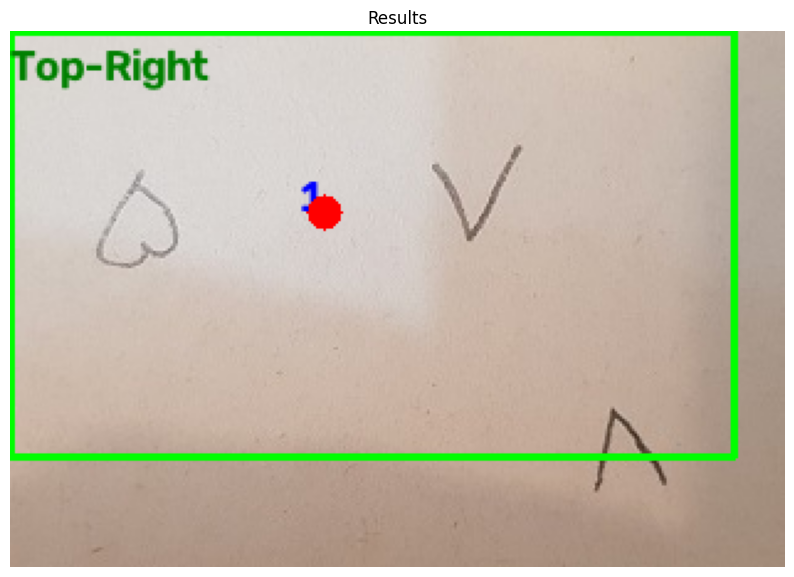

In [7]:
results_image = centers_image.copy()

x = top_right_number['x']
y = top_right_number['y']
width = top_right_number['width']
height = top_right_number['height']
center_x = top_right_number['center_x']
center_y = top_right_number['center_y']

cv2.rectangle(results_image, (x, y), (x + width, y + height), (0, 255, 0), 2)

cv2.circle(results_image, (center_x, center_y), 7, (0, 0, 255), -1)

cv2.putText(results_image, 'Top-Right', (x, max(20, y - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 128, 0), 2)

plt.figure(figsize=(10, 7))

plt.imshow(cv2.cvtColor(results_image, cv2.COLOR_BGR2RGB))
plt.title('Results')
plt.axis('off')

plt.show()

In [10]:
output_images = {
    'Exercise-10-Centers.png': centers_image,
    'Exercise-10-Top-Right-Number.png': results_image,
}

for filename, output_image in output_images.items():
  output_path = '/content/' + filename
  cv2.imwrite(output_path, output_image)
  print('Saved:', filename)
  files.download(output_path)
  print('Downloaded:', filename)

Saved: Exercise-10-Centers.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: Exercise-10-Centers.png
Saved: Exercise-10-Top-Right-Number.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: Exercise-10-Top-Right-Number.png


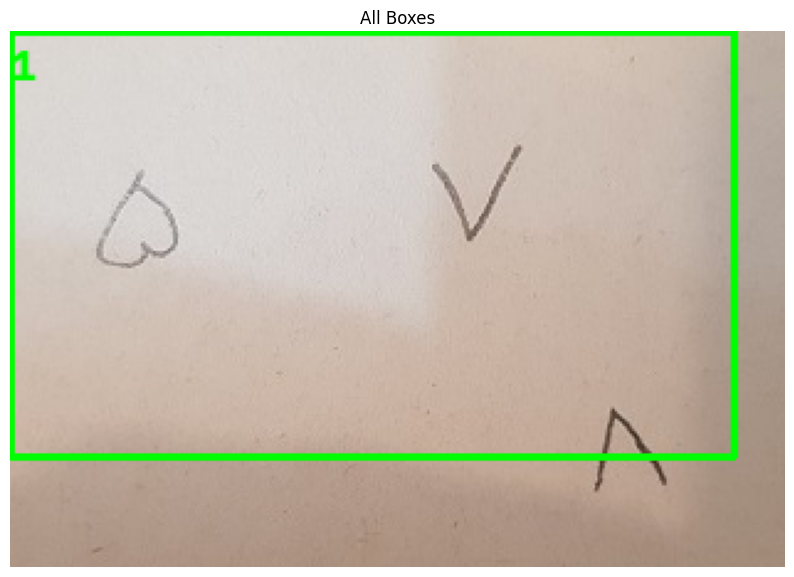

In [11]:
all_boxes_image = input_image.copy()

for number_id, item in enumerate(number_contours, start=1):
  x = item['x']
  y = item['y']
  width = item['width']
  height = item['height']

  cv2.rectangle(all_boxes_image, (x, y), (x + width, y + height), (0, 255, 0), 2)

  cv2.putText(all_boxes_image, str(number_id), (x, max(20, y - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

plt.figure(figsize=(10, 7))

plt.imshow(cv2.cvtColor(all_boxes_image, cv2.COLOR_BGR2RGB))
plt.title('All Boxes')
plt.axis('off')

plt.show()

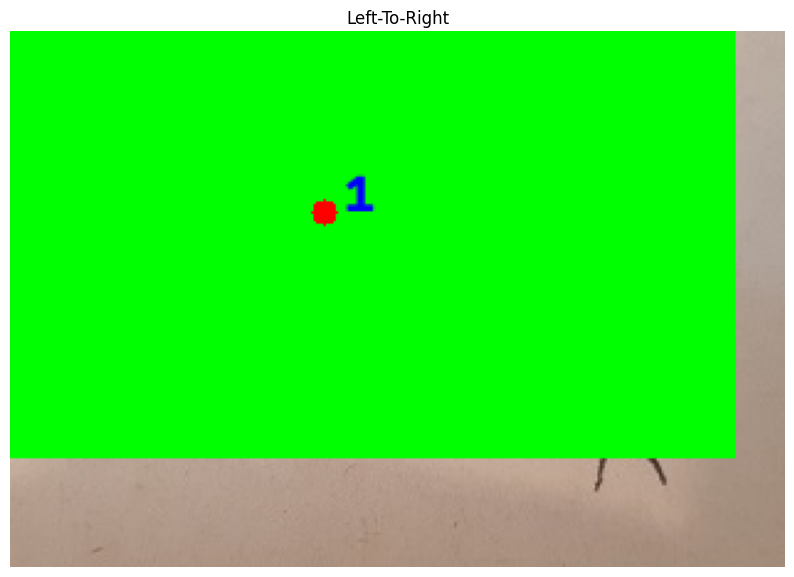

In [13]:
left_to_right_number = sorted(number_contours, key=lambda item: item['center_x'])

left_to_right_image = input_image.copy()

for order, item, in enumerate(left_to_right_number, start=1):
  x = item['x']
  y = item['y']
  width = item['width']
  height = item['height']

  cv2.rectangle(left_to_right_image, (x, y), (x + width, y + height), (0, 255, 0), -1)

  cv2.circle(left_to_right_image, (item['center_x'], item['center_y']), 5, (0, 0, 255), -1)

  cv2.putText(left_to_right_image, str(order), (item['center_x'] + 8, item['center_y']), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)

plt.figure(figsize=(10, 7))

plt.imshow(cv2.cvtColor(left_to_right_image, cv2.COLOR_BGR2RGB))
plt.title('Left-To-Right')
plt.axis('off')

plt.show()

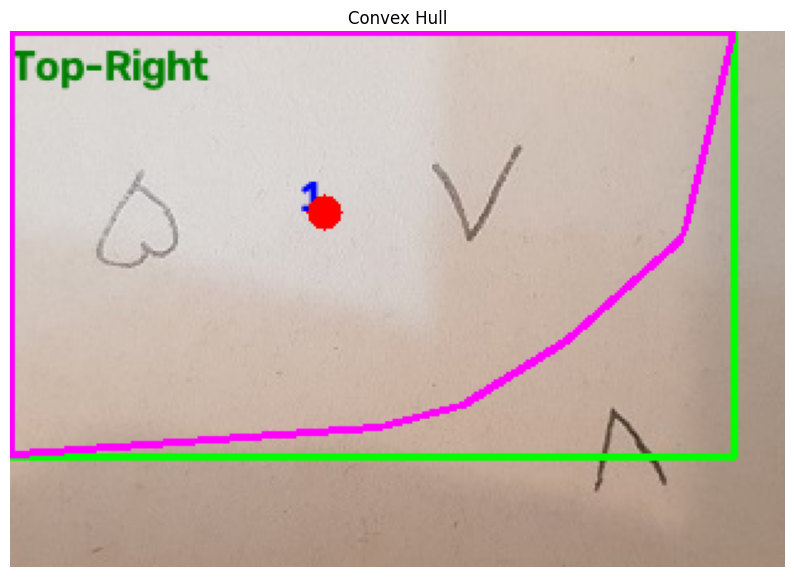

In [14]:
hull_image = results_image.copy()
selected_contour = top_right_number['contour']
hull = cv2.convexHull(selected_contour)

cv2.drawContours(hull_image, [hull], -1, (255, 0, 255), 2)

plt.figure(figsize=(10, 7))

plt.imshow(cv2.cvtColor(hull_image, cv2.COLOR_BGR2RGB))
plt.title('Convex Hull')
plt.axis('off')

plt.show()

In [17]:
def collect_valid_contours(contours, min_area):
  valid_contours = []

  for contour in contours:
    area = cv2.contourArea(contour)
    if area < min_area:
      continue

    moments = cv2.moments(contour)
    if moments['m00'] == 0:
      continue

    center_x = int(moments['m10'] / moments['m00'])
    center_y = int(moments['m01'] / moments['m00'])
    x, y, w, h = cv2.boundingRect(contour)

    valid_contours.append({
        'contour': contour,
        'center_x': center_x,
        'center_y': center_y,
        'area': area
    })
  return valid_contours

area_thresholds = [5, 20, 50, 100]
area_filter_counts = {}

for area_threshold in area_thresholds:
  valid_contours = collect_valid_contours(contours, area_threshold)
  area_filter_counts[area_threshold] = len(valid_contours)

print('Valid Contour Count By Area Threshold:')
for area_threshold, count in area_filter_counts.items():
  print(f'  {area_threshold}: {count}')

Valid Contour Count By Area Threshold:
  5: 1
  20: 1
  50: 1
  100: 1


In [18]:
extra_output_images = {
    'Exercise-10-All-Boxes.png': all_boxes_image,
    'Exercise-10-Left-To-Right.png': left_to_right_image,
    'Exercise-10-Convex-Hull.png': hull_image,
}

for filename, output_image in extra_output_images.items():
  output_path = '/content/' + filename
  cv2.imwrite(output_path, output_image)
  print('Saved:', filename)
  files.download(output_path)
  print('Downloaded:', filename)

Saved: Exercise-10-All-Boxes.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: Exercise-10-All-Boxes.png
Saved: Exercise-10-Left-To-Right.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: Exercise-10-Left-To-Right.png
Saved: Exercise-10-Convex-Hull.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: Exercise-10-Convex-Hull.png
